# Chapter 35: Entry, Scale, Contestability, and Strategic Deterrence

This notebook reruns four worked examples from the chapter: how many plants fit at minimum efficient scale, when to split an overloaded sorting hub, how a license cap keeps bakery profit positive, and how rank-sensitive attention turns a small quality gap into a superstar. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def mes_room(mes, demand):
    """minimum-efficient-scale: MES ratio and the most equal firms that each reach MES.

    Book (ch035): 40,000 / 150,000 = 0.2667, three firms; 25,000 / 150,000 = 0.1667, six firms.
    """
    ratio = mes / demand
    firms = math.floor(demand / mes + 1e-9)
    return {"ratio": ratio, "firms": firms, "share_next": demand / (firms + 1)}


def mes_unit_cost(q, floor=50.0, left=40_000, right=70_000):
    """Illustrative unit cost with a flat floor between `left` and `right` (ch035 shape: 72 at 20,000, 56 at 100,000)."""
    if q < left:
        return floor + 22 * (left - q) / (left - 20_000)
    if q <= right:
        return floor
    return floor + 6 * (q - right) / 30_000


def hub_cost(Q, F=80_000, c=4, b=0.0008, hubs=1):
    """diseconomies-of-scale: total cost of `hubs` equal hubs sharing Q, C(q) = F + c q + b q^2.

    Book (ch035): one hub at 16,000 costs 348,800 (21.80 each); two cost 2(163,200) = 326,400;
    Q* = sqrt(F / b) = 10,000 with AC 20; b = 0.0003 gives 220,800.
    """
    q = Q / hubs
    each = F + c * q + b * q * q
    return {"q": q, "each": each, "total": hubs * each, "ac": hubs * each / Q,
            "q_star": math.sqrt(F / b), "ac_min": 2 * math.sqrt(F * b) + c}


def free_entry_count(a, b, F, cap=None):
    """free-entry-zero-profit-condition: demand Q = a - b p, firm cost C(q) = F + q^2.

    Each firm supplies q = p / 2. Free entry drives p to minimum average cost 2 sqrt(F);
    a license cap below the free-entry count keeps price higher. Book (ch035): a = 1200,
    b = 30, F = 144 gives p = 24, q = 12, n = 40; with 30 firms p = 26.67 and profit 33.78;
    with 35 licenses p = 25.26, q = 12.63, profit 15.56.
    """
    q_min = math.sqrt(F)
    p_free = 2 * q_min
    n_free = (a - b * p_free) / q_min
    n = n_free if cap is None else min(cap, n_free)
    p = a / (n / 2 + b)
    q = p / 2
    profit = p * q - F - q * q
    return {"n_free": n_free, "n": n, "p": p, "q": q, "Q": n * q, "profit": profit,
            "binding": cap is not None and cap < n_free}


def superstar_share(z_a, z_b, kappa):
    """power-law-superstar: s_A = z_A^k / (z_A^k + z_B^k) = 1 / (1 + (z_B/z_A)^k).

    Book (ch035): 100 vs 97 at kappa 80 gives 0.9196; at kappa 4 gives 0.5304.
    """
    return 1.0 / (1.0 + (z_b / z_a) ** kappa)


plt.rcParams.update(HOUSE_RC)


industrial = SimpleNamespace(mes_room=mes_room, mes_unit_cost=mes_unit_cost, hub_cost=hub_cost, free_entry_count=free_entry_count, superstar_share=superstar_share)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'minimum-efficient-scale': {'mes': 40000,
                             'demand': 150000,
                             'ratio': 0.2667,
                             'firms': 3,
                             'share_four': 37500,
                             'mes_low': 25000,
                             'ratio_low': 0.1667,
                             'firms_low': 6,
                             'unit_costs': (72, 50, 50, 56),
                             'floor': 50},
 'diseconomies-of-scale': {'F': 80000,
                           'c': 4,
                           'b': 0.0008,
                           'Q': 16000,
                           'q_star': 10000,
                           'ac_min': 20,
                           'cost_6000': 132800,
                           'ac_6000': 22.13,
                           'cost_one': 348800,
                           'ac_one': 21.8,
                           'each_two': 163200,
                           'cost_two': 326400,
                           'saving': 22400,
                           'b_low': 0.0003,
                           'cost_one_low': 220800,
                           'ac_one_low': 13.8},
 'free-entry-zero-profit-condition': {'a': 1200,
                                      'b': 30,
                                      'F': 144,
                                      'p': 24,
                                      'q': 12,
                                      'Q': 480,
                                      'n': 40,
                                      'revenue': 288,
                                      'n30_p': 26.67,
                                      'n30_q': 13.33,
                                      'n30_profit': 33.78,
                                      'cap': 35,
                                      'cap_p': 25.26,
                                      'cap_q': 12.63,
                                      'cap_profit': 15.56},
 'power-law-superstar': {'z_a': 100,
                         'z_b': 97,
                         'kappa': 80,
                         'viewers': 500000,
                         'price': 3,
                         's_a': 0.9196,
                         'aud_a': 459800,
                         'aud_b': 40200,
                         'rev_a': 1379000,
                         'rev_b': 120600,
                         'ratio': 11.4,
                         'kappa_low': 4,
                         's_a_low': 0.5304,
                         'aud_a_low': 265200,
                         'aud_b_low': 234800},
 'constructed': {'minimum-efficient-scale': {'mes': [50000], 'demand': [75000, 300000]},
                 'diseconomies-of-scale': {'b': [0.0012], 'hubs': [3]},
                 'free-entry-zero-profit-condition': {'n': [45]},
                 'power-law-superstar': {'kappa': [1, 20], 'z_b': [90, 99]}}}


def small(x, digits=6):
    return f"{x:.{digits}f}"


def mes_picture(mes=40_000, demand=150_000):
    res = industrial.mes_room(mes, demand)
    firms = res["firms"]
    fig, (ax, bx) = new_figure(ncols=2)
    qs = np.linspace(15_000, 110_000, 300)
    ax.plot(qs / 1000, [industrial.mes_unit_cost(q, left=mes) for q in qs], color=PALETTE["navy"], linewidth=2.2)
    mark(ax, mes / 1000, 50, f"MES = {num(mes, 0)}", col="terracotta", dx=6, dy=10)
    ax.set_xlim(10, 115)
    ax.set_ylim(40, 85)
    ax.set_xlabel("Annual output (thousand units)")
    ax.set_ylabel("Unit cost ($)")
    left = 0.0
    for i in range(firms):
        bx.barh(0, mes / 1000, left=left, color=PALETTE["teal"], edgecolor="white", height=0.5)
        left += mes / 1000
    rest = demand / 1000 - left
    if rest > 1e-9:
        bx.barh(0, rest, left=left, color=PALETTE["light"], edgecolor="white", height=0.5)
    bx.set_xlim(0, max(demand / 1000, 1) * 1.05)
    bx.set_ylim(-0.6, 1.1)
    bx.set_yticks([])
    label(bx, 0, 0.3, f"{plural(firms, 'block')} of {num(mes, 0)} fit in demand {num(demand, 0)}", col="ink",
          dx=2, dy=8)
    bx.set_xlabel("Market demand (thousand units)")
    bx.set_ylabel("Demand split into MES blocks")
    share_next = res["share_next"]
    metrics = {"MES ratio": num(res["ratio"], 4), "Most equal firms at MES": str(firms),
               f"Output each with {firms + 1} equal firms": num(share_next, 0)}
    interp = (f"MES ratio = {num(mes, 0)} / {num(demand, 0)} = {num(res['ratio'], 4)}. {firms} x {num(mes, 0)} = "
              f"{num(firms * mes, 0)} fits within demand, but {firms + 1} equal firms would each sell "
              f"{num(demand, 0)} / {firms + 1} = {num(share_next, 0)}, below MES. So at most "
              f"{plural(firms, 'equal firm')} can reach the cost floor of $50.")
    steps = [f"MES ratio = {num(mes, 0)} / {num(demand, 0)} = {num(res['ratio'], 4)}",
             f"{firms} x {num(mes, 0)} = {num(firms * mes, 0)}, within {num(demand, 0)}",
             f"{num(demand, 0)} / {firms + 1} = {num(share_next, 0)}, below {num(mes, 0)}",
             f"Most equal efficient firms: {firms}"]
    alt = (f"Left: unit cost falls to a $50 floor that starts at {num(mes, 0)} units. Right: demand of "
           f"{num(demand, 0)} units split into {plural(firms, 'block')} of {num(mes, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def hub_picture(b=0.0008, hubs=1):
    bv = BV["diseconomies-of-scale"]
    F, c, Q = bv["F"], bv["c"], bv["Q"]
    res = industrial.hub_cost(Q, F, c, b, hubs)
    one = industrial.hub_cost(Q, F, c, b, 1)
    fig, ax = new_figure()
    qs = np.linspace(2_000, 20_000, 300)
    ax.plot(qs, F / qs + c + b * qs, color=PALETTE["navy"], linewidth=2.2, label="average cost of one hub")
    for h, col in ((1, "grey"), (2, "grey"), (3, "grey")):
        r = industrial.hub_cost(Q, F, c, b, h)
        if h != hubs:
            ax.scatter([r["q"]], [r["ac"]], s=30, color=PALETTE[col], zorder=4)
    mark(ax, res["q"], res["ac"], f"{plural(hubs, 'hub')}: {money(res['ac'])} per parcel", col="terracotta",
         dx=-8 if hubs == 1 else 8, dy=10, ha="right" if hubs == 1 else "left")
    vline(ax, res["q_star"], f"Q* = {num(res['q_star'], 0)}", col="teal", y_frac=0.97)
    ax.set_xlim(2_000, 20_000)
    ax.set_ylim(0, 60)
    ax.legend(loc="lower right", frameon=False)
    ax.set_xlabel("Parcels per hub per month")
    ax.set_ylabel("Average cost ($ per parcel)")
    q = res["q"]
    t_c, t_b = c * q, b * q * q
    save = one["total"] - res["total"]
    if hubs == 1:
        verdict = "This is the single-hub benchmark."
    elif save > 0:
        verdict = f"Splitting saves {money(save)} against one hub."
    else:
        verdict = f"Splitting costs {money(-save)} more than one hub, so the extra setup is not worth it."
    metrics = {"Parcels per hub": num(q), "Cost per hub": money(res["each"]), "Total cost": money(res["total"]),
               "Cost per parcel": money(res["ac"]), "One-hub total": money(one["total"]),
               "Saving against one hub": money(save) if save >= 0 else f"-{money(-save)}",
               "Q* (minimum average cost)": num(res["q_star"], 0)}
    each_line = (f"80,000 + 4 x {num(q)} + {b:g} x {num(q)}^2 = 80,000 + {num(t_c)} + {num(t_b)} = "
                 f"{money(res['each'])}")
    interp = (f"Each of {plural(hubs, 'hub')} handles 16,000 / {hubs} = {num(q)} parcels. {each_line}. Total cost is "
              f"{hubs} x {money(res['each'])} = {money(res['total'])}, or {money(res['ac'])} per parcel. Average "
              f"cost is lowest at Q* = sqrt(80,000 / {b:g}) = {num(res['q_star'], 0)}. {verdict}")
    steps = [f"q = 16,000 / {hubs} = {num(q)}", f"Cost per hub = {each_line}",
             f"Total = {hubs} x {money(res['each'])} = {money(res['total'])}",
             f"Per parcel = {money(res['total'])} / 16,000 = {money(res['ac'])}",
             f"One hub: {money(one['total'])}; difference {signed(save)}"]
    alt = (f"Average cost curve of one hub with quadratic coefficient {b:g}, lowest at {num(res['q_star'], 0)} "
           f"parcels. With {plural(hubs, 'hub')} each hub handles {num(q)} parcels at {money(res['ac'])} each.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def entry_picture(n=40):
    bv = BV["free-entry-zero-profit-condition"]
    res = industrial.free_entry_count(bv["a"], bv["b"], bv["F"], cap=n)
    m = res["n"]
    p, q = res["p"], res["q"]
    fig, ax = new_figure()
    ps = np.linspace(0, 40, 200)
    ax.plot(1200 - 30 * ps, ps, color=PALETTE["navy"], linewidth=2.2, label="demand Q = 1200 - 30p")
    ax.plot(m * ps / 2, ps, color=PALETTE["teal"], linewidth=2.2, label=f"supply of {num(m, 0)} firms, Q = {num(m, 0)}p/2")
    mark(ax, res["Q"], p, f"p = {num(p)}, Q = {num(res['Q'])}", col="terracotta", dx=8, dy=8)
    ax.axhline(24, color=PALETTE["grey"], linestyle="dashed", linewidth=1.2)
    label(ax, 30, 24, "minimum average cost 24", col="grey", dx=0, dy=-6, va="top")
    ax.set_xlim(0, 1000)
    ax.set_ylim(0, 40)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Loaves per day Q")
    ax.set_ylabel("Price p ($)")
    rev, sq = p * q, q * q
    if n > res["n_free"]:
        cap_text = f"The cap of {n} is above the free-entry count of 40, so it does not bind and 40 bakeries operate."
    elif n == res["n_free"]:
        cap_text = "Forty bakeries is the free-entry count."
    else:
        cap_text = f"Only {n} bakeries may operate, below the free-entry count of 40, so profit persists."
    metrics = {"Bakeries operating": num(m, 0), "Price p": num(p), "Output per bakery q": num(q),
               "Profit per bakery": money(res["profit"])}
    interp = (f"{cap_text} Market clearing {num(m, 0)}(p/2) = 1200 - 30p gives p = 2400 / (60 + {num(m, 0)}) = "
              f"{num(p)} and q = p/2 = {num(q)}. Profit = p^2/4 - 144 = {num(p * p / 4)} - 144 = "
              f"{money(res['profit'])}.")
    steps = [f"{num(m, 0)}(p/2) = 1200 - 30p", f"p = 2400 / (60 + {num(m, 0)}) = {num(p)}", f"q = p / 2 = {num(q)}",
             f"Revenue p q = p^2/2 = {num(rev, 4)}; cost 144 + q^2 = 144 + {num(sq, 4)} = {num(144 + sq, 4)}",
             f"Profit = {num(rev, 4)} - {num(144 + sq, 4)} = {money(res['profit'])}"]
    alt = (f"Demand Q = 1200 - 30p and the supply of {num(m, 0)} bakeries cross at p = {num(p)}; minimum average "
           f"cost is 24.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def superstar_picture(kappa=80, zb=97):
    bv = BV["power-law-superstar"]
    viewers, price = bv["viewers"], bv["price"]
    s = industrial.superstar_share(100, zb, kappa)
    x = (zb / 100) ** kappa
    aud_a, aud_b = viewers * s, viewers * (1 - s)
    ratio = aud_a / aud_b
    fig, (ax, bx) = new_figure(ncols=2)
    ks = np.logspace(0, np.log10(100), 200)
    ax.plot(ks, [industrial.superstar_share(100, zb, k) for k in ks], color=PALETTE["navy"], linewidth=2.2)
    mark(ax, kappa, s, f"s_A = {num(s, 4)}", col="terracotta", dx=-8 if kappa > 10 else 8, dy=-14,
         ha="right" if kappa > 10 else "left", va="top")
    ax.set_xscale("log")
    ax.set_xlim(1, 100)
    ax.set_ylim(0.4, 1.05)
    ax.set_xlabel("Attention sensitivity kappa (log scale)")
    ax.set_ylabel("A's audience share")
    bx.bar([0, 1], [aud_a / 1000, aud_b / 1000], color=[PALETTE["teal"], PALETTE["gold"]], width=0.6)
    bx.set_xticks([0, 1], ["A (score 100)", f"B (score {zb})"])
    for i, v in enumerate((aud_a, aud_b)):
        bx.annotate(num(v, 0), (i, v / 1000), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                    fontsize=10.5, color=PALETTE["ink"])
    bx.set_ylim(0, 560)
    bx.set_ylabel("Viewers (thousand)")
    bx.set_xlabel("Instructor")
    metrics = {"Share of A, s_A": num(s, 4), "Viewers of A": num(aud_a, 0), "Viewers of B": num(aud_b, 0),
               "Revenue of A": money(price * aud_a, 0), "Revenue of B": money(price * aud_b, 0),
               "Audience ratio A to B": num(ratio, 1)}
    xs = small(x, 9) if x < 0.01 else small(x)
    va, vb = num(aud_a, 1), num(aud_b, 1)
    gap = 100 - zb
    interp = (f"({zb}/100)^{kappa} = {xs}, so s_A = 1 / (1 + {xs}) = {small(s)}. A draws 500,000 x "
              f"{small(s, 8)} = {va} viewers and B {vb}, a ratio of 1 / {xs} = {num(ratio, 1)} to 1. At $3 a "
              f"viewer the revenues are {money(price * aud_a, 0)} and {money(price * aud_b, 0)}. A score gap of "
              f"{gap} point{'' if gap == 1 else 's'} out of 100 becomes this audience gap because attention is rank sensitive.")
    steps = [f"({zb}/100)^{kappa} = {xs}", f"s_A = 1 / (1 + {xs}) = {small(s)}",
             f"A: 500,000 x {small(s, 8)} = {va}; B: 500,000 - {va} = {vb}",
             f"Revenue: 3 x {va} = {money(price * aud_a, 0)}; 3 x {vb} = {money(price * aud_b, 0)}",
             f"Ratio = s_A / (1 - s_A) = 1 / {xs} = {num(ratio, 1)}"]
    alt = (f"Left: A's share rises with attention sensitivity; at kappa {kappa} and rival score {zb} it is "
           f"{num(s, 4)}. Right: audiences of {num(aud_a, 0)} for A and {num(aud_b, 0)} for B.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Minimum efficient scale: room for efficient firms

Unit cost reaches its \$50 floor at 40,000 units, and annual demand is 150,000.

$$\frac{40{,}000}{150{,}000}=0.2667$$

With automation the floor starts at 25,000:

$$\frac{25{,}000}{150{,}000}=0.1667$$

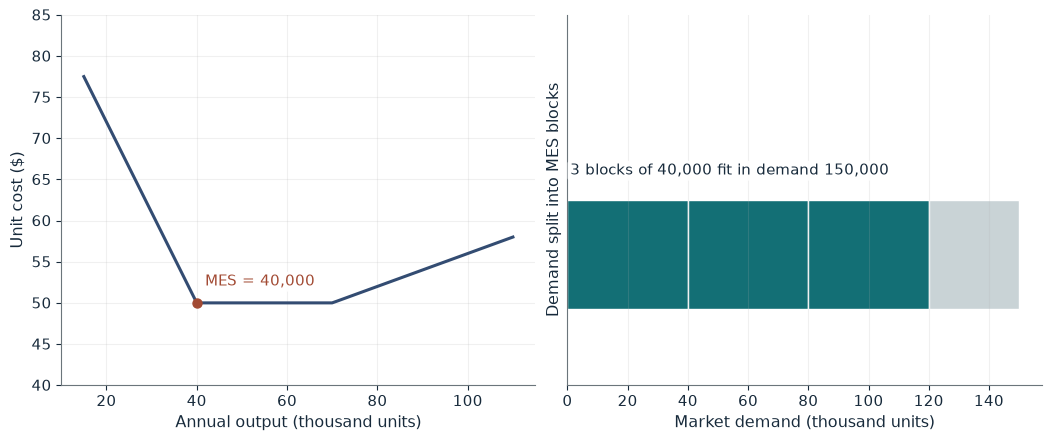

MES ratio                       0.2667
Most equal firms at MES         3
Output each with 4 equal firms  37,500

Worked steps:
  1. MES ratio = 40,000 / 150,000 = 0.2667
  2. 3 x 40,000 = 120,000, within 150,000
  3. 150,000 / 4 = 37,500, below 40,000
  4. Most equal efficient firms: 3

MES ratio = 40,000 / 150,000 = 0.2667. 3 x 40,000 = 120,000 fits within demand, but 4 equal firms would each sell 150,000 / 4 = 37,500, below MES. So at most 3 equal firms can reach the cost floor of $50.


In [2]:
show(mes_picture(mes=40_000, demand=150_000))

Change one input, `mes`, and hold the others at the book's values:

In [3]:
sweep(mes_picture, 'mes', [25000, 40000, 50000], {'demand': 150000}, ['MES ratio', 'Most equal firms at MES'])

mes | MES ratio | Most equal firms at MES
25000 | 0.1667 | 6
40000 | 0.2667 | 3
50000 | 0.3333 | 3


Three plants of 40,000 fit in 150,000; four equal firms would each sell 37,500, below MES. Lowering MES to 25,000 leaves room for six. Doubling demand with MES unchanged would also lower the ratio.

## 2. Diseconomies of scale: splitting an overloaded hub

A hub's monthly cost is

$$C(Q)=80{,}000+4Q+0.0008Q^2,$$

with the lowest average cost at

$$Q^*=\sqrt{\frac{80{,}000}{0.0008}}=10{,}000.$$

The operator handles 16,000 parcels.

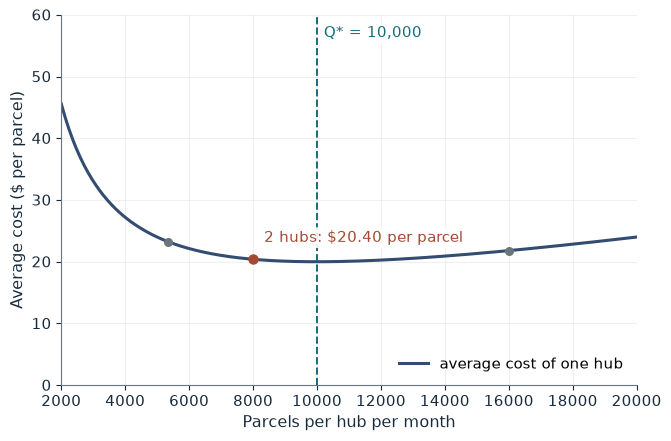

Parcels per hub            8,000.00
Cost per hub               $163,200.00
Total cost                 $326,400.00
Cost per parcel            $20.40
One-hub total              $348,800.00
Saving against one hub     $22,400.00
Q* (minimum average cost)  10,000

Worked steps:
  1. q = 16,000 / 2 = 8,000.00
  2. Cost per hub = 80,000 + 4 x 8,000.00 + 0.0008 x 8,000.00^2 = 80,000 + 32,000.00 + 51,200.00 = $163,200.00
  3. Total = 2 x $163,200.00 = $326,400.00
  4. Per parcel = $326,400.00 / 16,000 = $20.40
  5. One hub: $348,800.00; difference 22,400.00

Each of 2 hubs handles 16,000 / 2 = 8,000.00 parcels. 80,000 + 4 x 8,000.00 + 0.0008 x 8,000.00^2 = 80,000 + 32,000.00 + 51,200.00 = $163,200.00. Total cost is 2 x $163,200.00 = $326,400.00, or $20.40 per parcel. Average cost is lowest at Q* = sqrt(80,000 / 0.0008) = 10,000. Splitting saves $22,400.00 against one hub.


In [4]:
show(hub_picture(b=0.0008, hubs=2))

Change one input, `hubs`, and hold the others at the book's values:

In [5]:
sweep(hub_picture, 'hubs', [1, 2, 3], {'b': 0.0008}, ['Total cost', 'Cost per parcel', 'Saving against one hub'])

hubs | Total cost | Cost per parcel | Saving against one hub
1 | $348,800.00 | $21.80 | $0.00
2 | $326,400.00 | $20.40 | $22,400.00
3 | $372,266.67 | $23.27 | -$23,466.67


One hub costs \$348,800 (\$21.80 a parcel); two hubs cost \$326,400 and save \$22,400 despite the duplicated setup. With the coefficient at 0.0003 (`b=0.0003`) one hub costs \$220,800 and splitting no longer pays.

## 3. Free-entry zero-profit condition: free entry versus license caps

Demand is $Q_D=1200-30p$ and each bakery has cost $144+q^2$, so it supplies $q=p/2$. With 30 bakeries market clearing is

$$30\left(\frac{p}{2}\right)=1200-30p.$$

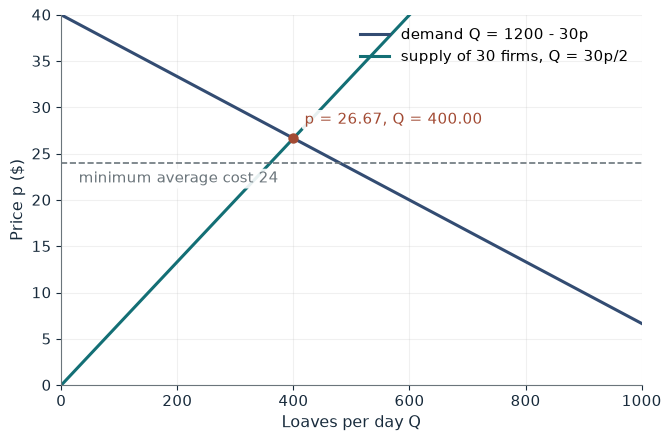

Bakeries operating   30
Price p              26.67
Output per bakery q  13.33
Profit per bakery    $33.78

Worked steps:
  1. 30(p/2) = 1200 - 30p
  2. p = 2400 / (60 + 30) = 26.67
  3. q = p / 2 = 13.33
  4. Revenue p q = p^2/2 = 355.5556; cost 144 + q^2 = 144 + 177.7778 = 321.7778
  5. Profit = 355.5556 - 321.7778 = $33.78

Only 30 bakeries may operate, below the free-entry count of 40, so profit persists. Market clearing 30(p/2) = 1200 - 30p gives p = 2400 / (60 + 30) = 26.67 and q = p/2 = 13.33. Profit = p^2/4 - 144 = 177.78 - 144 = $33.78.


In [6]:
show(entry_picture(n=30))

Change one input, `n`, and hold the others at the book's values:

In [7]:
sweep(entry_picture, 'n', [30, 35, 40, 45], {}, ['Bakeries operating', 'Price p', 'Profit per bakery'])

n | Bakeries operating | Price p | Profit per bakery
30 | 30 | 26.67 | $33.78
35 | 35 | 25.26 | $15.56
40 | 40 | 24.00 | $0.00
45 | 40 | 24.00 | $0.00


Thirty bakeries earn \$33.78 each and 35 licenses still leave \$15.56; only at 40 does price reach the minimum average cost of 24 and profit fall to zero. A cap of 45 does not bind.

## 4. Superstar markets: rank-sensitive attention

Scores are 100 and 97 and 500,000 viewers choose by the share rule

$$s_A=\frac{100^{80}}{100^{80}+97^{80}}=\frac{1}{1+0.97^{80}}\approx0.9196.$$

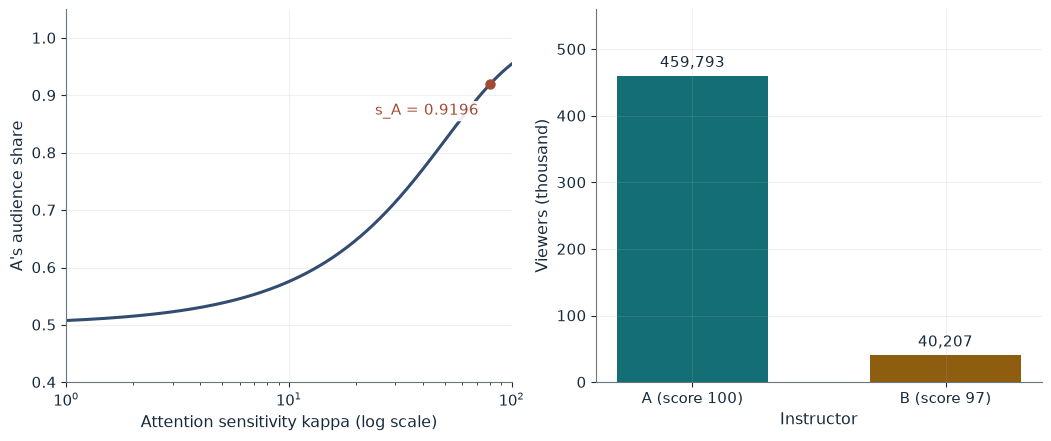

Share of A, s_A        0.9196
Viewers of A           459,793
Viewers of B           40,207
Revenue of A           $1,379,379
Revenue of B           $120,621
Audience ratio A to B  11.4

Worked steps:
  1. (97/100)^80 = 0.087446
  2. s_A = 1 / (1 + 0.087446) = 0.919586
  3. A: 500,000 x 0.91958610 = 459,793.0; B: 500,000 - 459,793.0 = 40,207.0
  4. Revenue: 3 x 459,793.0 = $1,379,379; 3 x 40,207.0 = $120,621
  5. Ratio = s_A / (1 - s_A) = 1 / 0.087446 = 11.4

(97/100)^80 = 0.087446, so s_A = 1 / (1 + 0.087446) = 0.919586. A draws 500,000 x 0.91958610 = 459,793.0 viewers and B 40,207.0, a ratio of 1 / 0.087446 = 11.4 to 1. At $3 a viewer the revenues are $1,379,379 and $120,621. A score gap of 3 points out of 100 becomes this audience gap because attention is rank sensitive.


In [8]:
show(superstar_picture(kappa=80, zb=97))

Change one input, `kappa`, and hold the others at the book's values:

In [9]:
sweep(superstar_picture, 'kappa', [1, 4, 20, 80], {'zb': 97}, ['Share of A, s_A', 'Viewers of A', 'Audience ratio A to B'])

kappa | Share of A, s_A | Viewers of A | Audience ratio A to B
1 | 0.5076 | 253,807 | 1.0
4 | 0.5304 | 265,211 | 1.1
20 | 0.6478 | 323,877 | 1.8
80 | 0.9196 | 459,793 | 11.4


At kappa 80 the exact audiences are 459,793 and 40,207 (the book rounds to 459,800 and 40,200), a ratio of 11.4 to 1. At kappa 4 the share is 0.5304, close to an even split.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

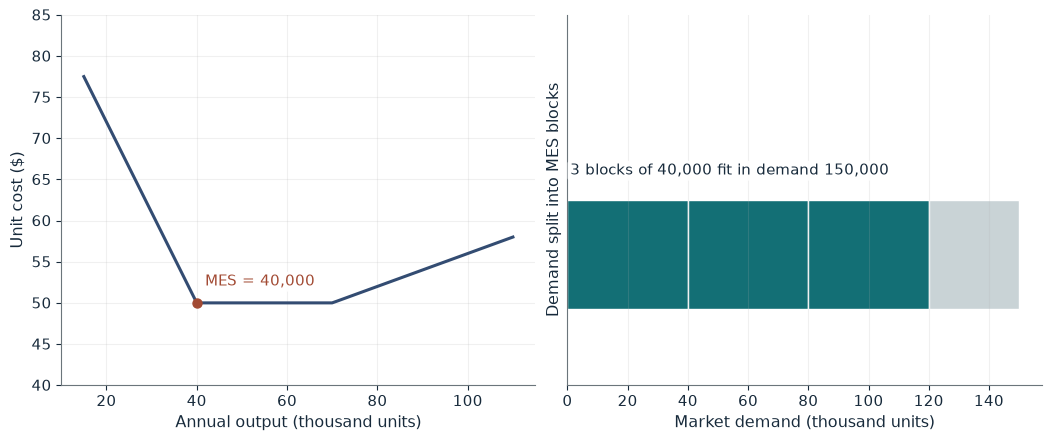

MES ratio                       0.2667
Most equal firms at MES         3
Output each with 4 equal firms  37,500

Worked steps:
  1. MES ratio = 40,000 / 150,000 = 0.2667
  2. 3 x 40,000 = 120,000, within 150,000
  3. 150,000 / 4 = 37,500, below 40,000
  4. Most equal efficient firms: 3

MES ratio = 40,000 / 150,000 = 0.2667. 3 x 40,000 = 120,000 fits within demand, but 4 equal firms would each sell 150,000 / 4 = 37,500, below MES. So at most 3 equal firms can reach the cost floor of $50.


In [10]:
show(mes_picture(mes=40_000, demand=150_000))

## Practice

**1.** At MES 50,000 and demand 300,000, how many equal efficient firms fit?

<details><summary>Answer</summary>

300,000 / 50,000 = 6, and the MES ratio is 0.1667.

</details>

**2.** Two hubs with quadratic coefficient 0.0003: what is total cost, and does splitting pay?

<details><summary>Answer</summary>

Each costs 80,000 + 32,000 + 0.0003 x 8,000^2 = 131,200, so the total is 262,400, more than one hub's 220,800: splitting loses 41,600.

</details>

**3.** At kappa 20 and scores 100 and 97, what is A's share?

<details><summary>Answer</summary>

0.97^20 = 0.5438, so s_A = 1 / 1.5438 = 0.648.

</details>